# Clustering and PCA

In [1]:
# from sklearn.preprocessing import PolynomialFeatures
# from sklearn.linear_model import LinearRegression, Lasso, Ridge
# from sklearn.metrics import mean_squared_error
# from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.mixture import GaussianMixture
from scipy.stats import multivariate_normal
from sklearn.metrics import silhouette_score
import hashlib
import pandas as pd
import random
import cv2
from PIL import Image


In [2]:
username = "gracy.garg"
seed = 42
# seed = int ( hashlib . sha256 ( username . encode () ) . hexdigest () , 16)
# seed = seed % (2**32)
# print(f"Seed for {username}: {seed}")

# > Include username in plots

In [3]:
def add_username_to_plot(username="gracy.garg"):
    """
    Adds the username to the top-right corner of the current plot.
    """
    plt.text(
        0.95, 0.95, username,
        ha='right', va='top',
        transform=plt.gca().transAxes,
        fontsize=10, color='gray', alpha=0.7
    )

# Q2.0 K-Means Clusteing

# > Load Dataset

In [4]:
# Load the dataset
try:
    data = pd.read_csv("given_dataset.csv")
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print("Error: 'given_dataset.csv' not found.")

# Drop Irrelevant Column: 'CustomerID'
if 'CustomerID' in data.columns:
    data = data.drop('CustomerID', axis=1)
    print("Dropped 'CustomerID' column.")

# Handle Categorical Data: 'Genre'
data = pd.get_dummies(data, columns=['Genre'], drop_first=True) 
print("Applied One-Hot Encoding to 'Genre'.")

# Ensure all columns are numeric and handle missing values
for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Impute Missing Values (NaN) using the mean of the column
data = data.fillna(data.mean())
print(f"Handled missing values using mean imputation.")

# Convert DataFrame to NumPy array X
X_unscaled = data.values
scaler = StandardScaler()
X = scaler.fit_transform(X_unscaled)
print("Data scaled using StandardScaler.")

X = X.astype(float) # Final check for float type
print(f"Shape of the final numeric dataset X: {X.shape}")

Dataset loaded successfully.
Dropped 'CustomerID' column.
Applied One-Hot Encoding to 'Genre'.
Handled missing values using mean imputation.
Data scaled using StandardScaler.
Shape of the final numeric dataset X: (200, 4)


### Q2.1 Implement a K-Means Class

In [5]:
class KMeansCustom:
    def __init__(self, k=3, max_iters=100, tol=1e-4, random_state=None):
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.random_state = random_state
        self.centroids = None

    def fit(self, X):
        np.random.seed(self.random_state)
        # Initialize centroids randomly from the data points
        if self.k > len(X):
             raise ValueError("k cannot be greater than the number of samples.")
        
        random_indices = np.random.choice(len(X), self.k, replace=False)
        self.centroids = X[random_indices]

        for _ in range(self.max_iters):
            # E-step: Assign clusters
            labels = self._assign_clusters(X)

            # M-step: Calculate new centroids
            new_centroids = []
            for i in range(self.k):
                cluster_points = X[labels == i]
                if len(cluster_points) > 0:
                    new_centroids.append(cluster_points.mean(axis=0))
                else:
                    new_centroids.append(self.centroids[i])
            new_centroids = np.array(new_centroids)

            # Check for convergence
            if np.linalg.norm(self.centroids - new_centroids) < self.tol:
                break
            self.centroids = new_centroids

    def _assign_clusters(self, X):
        """Assigns each data point to the closest centroid."""
        distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
        return np.argmin(distances, axis=1)

    def predict(self, X):
        """Assigns a cluster number to each data-point."""
        if self.centroids is None:
            raise Exception("Model not fitted yet. Call fit() first.")
        return self._assign_clusters(X)

    def getCost(self, X):
        """Returns the cost (WCSS) of K-Means."""
        if self.centroids is None:
            raise Exception("Model not fitted yet. Call fit() first.")
            
        labels = self._assign_clusters(X)
        cost = 0
        for i in range(self.k):
            cluster_points = X[labels == i]
            if len(cluster_points) > 0:
                cost += np.sum((cluster_points - self.centroids[i])**2)
        return cost


### Q2.2 Determine the Optimal Number of Clusters

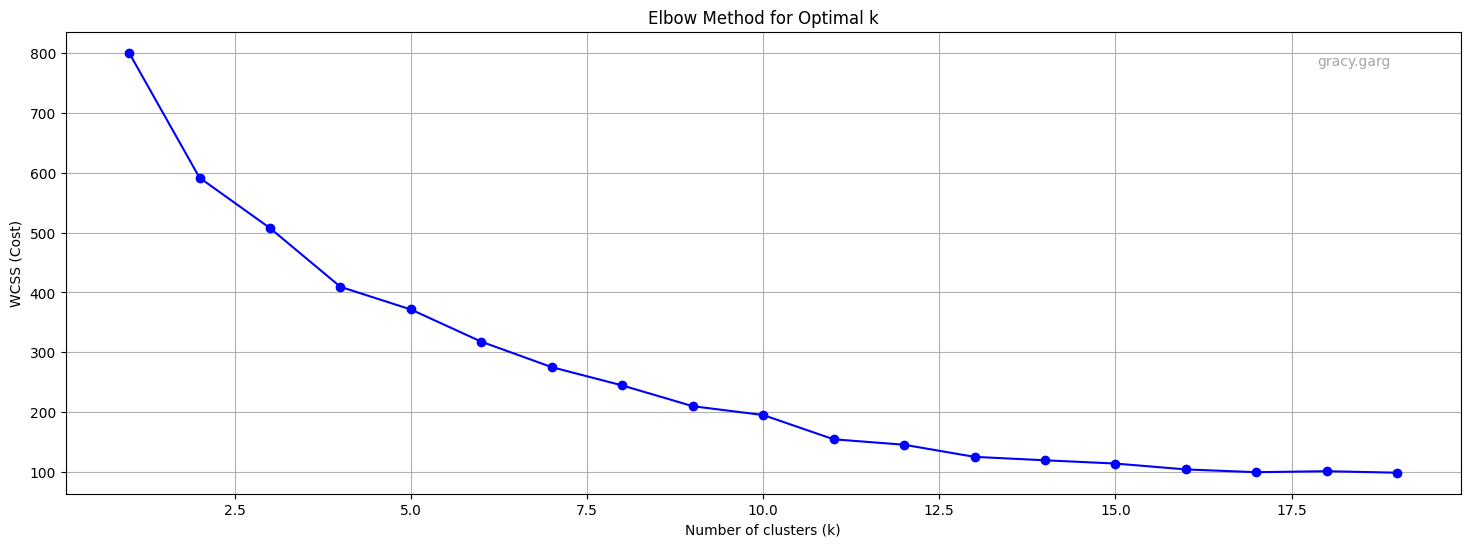

In [6]:
# Using Elbow Method
wcss = []
K_range = range(1, 20) # Test k from 1 to 20

for k in K_range:
    km = KMeansCustom(k=k, random_state=42)
    km.fit(X) 
    wcss.append(km.getCost(X))

plt.figure(figsize=(18, 6))
plt.plot(K_range, wcss, 'bo-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS (Cost)')
plt.title(f'Elbow Method for Optimal k')
add_username_to_plot(username)
plt.grid(True)
plt.show()

From the Elbow plot, we can observe the point where the WCSS starts to decrease more slowly, indicating the optimal number of clusters (k). This is typically where the 'elbow' occurs in the plot.  
The optimal value of k according to the elbow method is k = 13 as adding more clusters beyond this point provides diminishing returns in reducing WCSS.

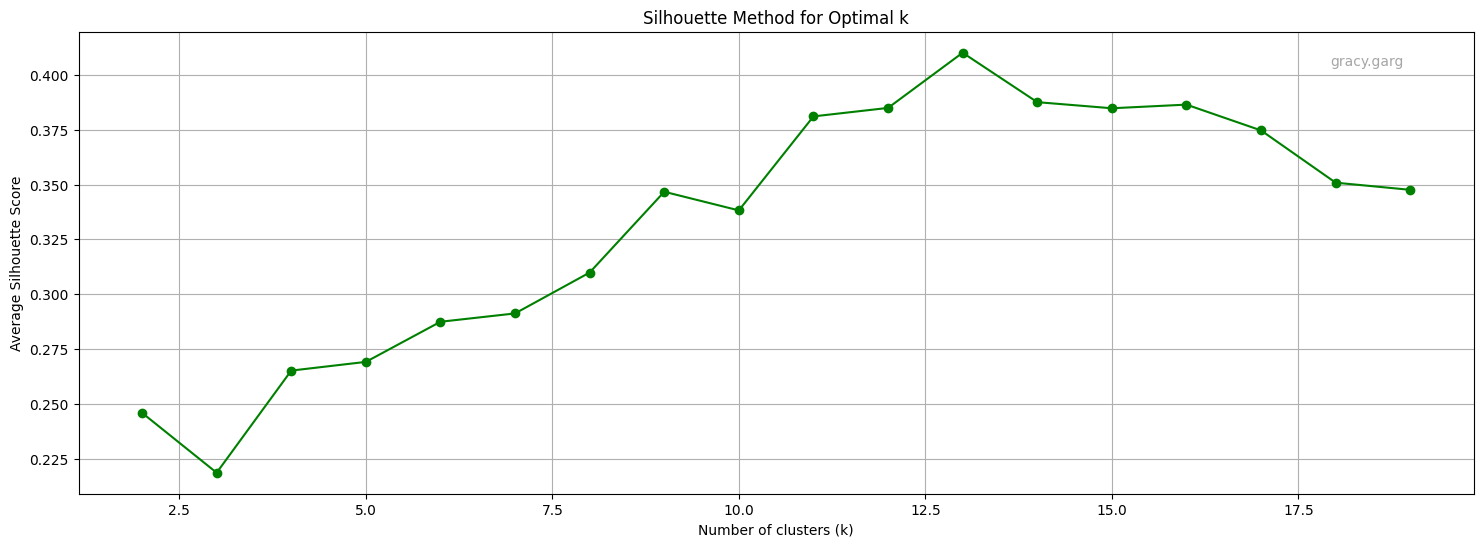

The value of k that maximizes the silhouette score is k = 13 (Score: 0.4101).

What can you say about the clusters obtained at the optimal value?
At k = 13, the clusters are generally considered well-separated and dense, as indicated by the highest average silhouette score. A score closer to +1 means the data point fits very well in its own cluster and is far from others. The highest value obtained here implies decent clustering, but not perfect separation.


In [7]:
# Using Silhouette Method
sil_scores = []
# Silhouette is not defined for k=1, so we start from k=2
K_range_sil = range(2, 20) 

for k in K_range_sil:
    km = KMeansCustom(k=k, random_state=seed)
    km.fit(X)
    labels = km.predict(X)
    sil_scores.append(silhouette_score(X, labels))

plt.figure(figsize=(18, 6))
plt.plot(K_range_sil, sil_scores, 'go-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Average Silhouette Score')
plt.title(f'Silhouette Method for Optimal k')
add_username_to_plot(username)
plt.grid(True)
plt.show()

if sil_scores:
    best_k = K_range_sil[np.argmax(sil_scores)]
    max_score = np.max(sil_scores)
    print(f"The value of k that maximizes the silhouette score is k = {best_k} (Score: {max_score:.4f}).")
    print("\nWhat can you say about the clusters obtained at the optimal value?")
    print(f"At k = {best_k}, the clusters are generally considered well-separated and dense, as indicated by the highest average silhouette score. A score closer to +1 means the data point fits very well in its own cluster and is far from others. The highest value obtained here implies decent clustering, but not perfect separation.")
else:
    print("Could not compute silhouette scores. Check data and K-Means implementation.")

# Q3 Gaussian Mixture Models

### Q3.1 Implement the GMM Class

Final Log-Likelihood for k=13: 485.8108


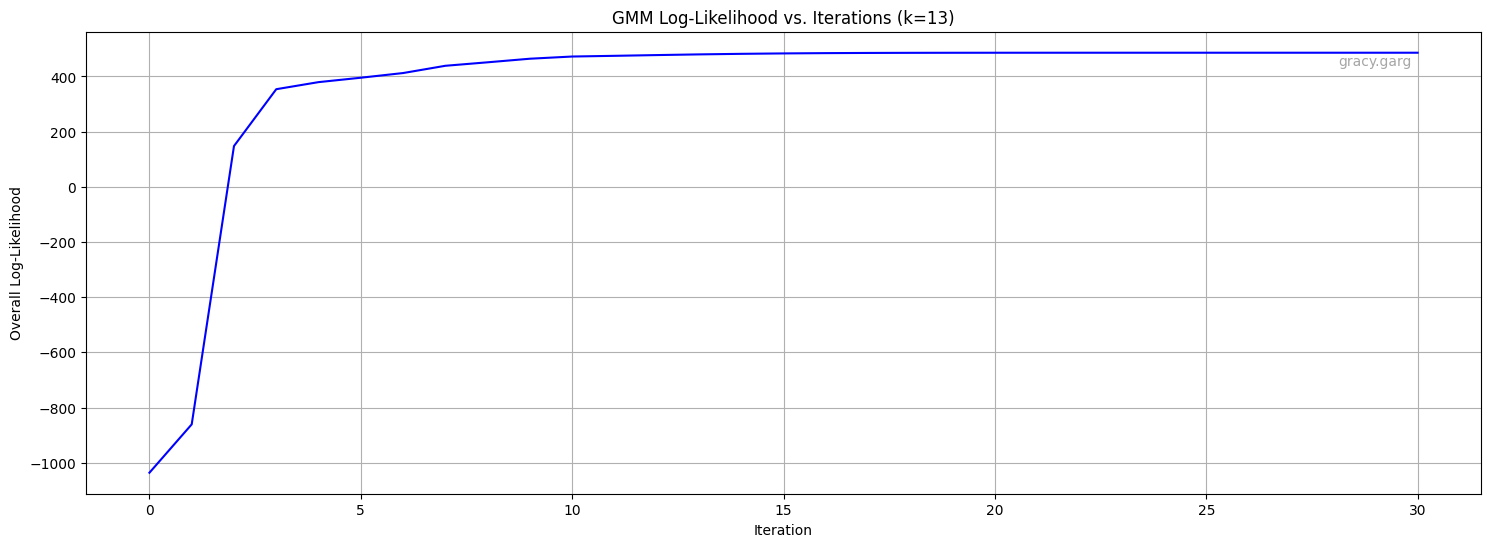

In [8]:
class GMMCustom:
    def __init__(self, k=3, max_iters=100, tol=1e-4, random_state=None):
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.random_state = random_state
        self.likelihood_history = []
        self.means = None
        self.covariances = None
        self.weights = None
        self.n_features = None

    def _initialize_parameters(self, X):
        """Initializes means, covariances, and weights."""
        np.random.seed(self.random_state)
        n_samples, self.n_features = X.shape

        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.means = X[random_indices]

        self.covariances = np.array([np.cov(X, rowvar=False) + 1e-6 * np.eye(self.n_features)] * self.k)
        self.weights = np.ones(self.k) / self.k

    def _expectation_step(self, X):
        """E-step: Calculate responsibilities (gamma_ic)."""
        n_samples = X.shape[0]
        # responsibilities (gamma_ic): P(c|xi)
        responsibilities = np.zeros((n_samples, self.k))

        for c in range(self.k):
            # Multivariate Gaussian Probability Density Function (PDF)
            # Add a small epsilon for numerical stability in case of singular matrices
            try:
                pdf = multivariate_normal.pdf(X, mean=self.means[c], cov=self.covariances[c], allow_singular=True)
            except np.linalg.LinAlgError:
                # Fallback for numerical instability
                print(f"Warning: LinAlgError for cluster {c}. Adding jitter.")
            responsibilities[:, c] = self.weights[c] * pdf
        
        # Normalize responsibilities: sum_c P(c|xi) = 1
        sum_resp = responsibilities.sum(axis=1)[:, np.newaxis]
        sum_resp[sum_resp == 0] = 1e-10         # Handle zero division 
        responsibilities /= sum_resp
        
        return responsibilities

    def _maximization_step(self, X, responsibilities):
        """M-step: Update parameters (weights, means, and covariances)."""
        n_samples = X.shape[0]
        
        # N_c: effective number of points in cluster c
        N_c = responsibilities.sum(axis=0)

        for c in range(self.k):
            if N_c[c] > 0:
                # Update Mean & Covariance (mu_c)
                self.means[c] = np.sum(responsibilities[:, c][:, np.newaxis] * X, axis=0) / N_c[c]
                diff = X - self.means[c]
                self.covariances[c] = (responsibilities[:, c][:, np.newaxis] * diff).T @ diff / N_c[c]
                
                # Add a tiny amount to the diagonal for stability
                self.covariances[c] += 1e-6 * np.eye(self.n_features)

                # Update Weights (pi_c)
                self.weights[c] = N_c[c] / n_samples

    def getLikelihood(self, X, responsibilities=None):
        """Returns the overall log-likelihood of the dataset (ln L)."""
        if responsibilities is None:
            # If not provided, calculate it in the E-step first
            responsibilities = self._expectation_step(X)
            
        # P(xi, c) = pi_c * N(xi | mu_c, Sigma_c)
        weighted_pdfs = np.zeros((X.shape[0], self.k))
        for c in range(self.k):
             try:
                pdf = multivariate_normal.pdf(X, mean=self.means[c], cov=self.covariances[c], allow_singular=True)
             except np.linalg.LinAlgError:
                pdf = multivariate_normal.pdf(
                    X, 
                    mean=self.means[c], 
                    cov=self.covariances[c] + 1e-6 * np.eye(self.n_features), 
                    allow_singular=True
                )
             weighted_pdfs[:, c] = self.weights[c] * pdf

        # Marginal Likelihood L = P(xi) = sum_c P(xi, c)
        marginal_likelihood = np.sum(weighted_pdfs, axis=1)
        
        # Log-Likelihood (ln L)
        log_likelihood = np.sum(np.log(marginal_likelihood[marginal_likelihood > 0]))
        return log_likelihood

    def fit(self, X):
        """Implements the Expectation-Maximization (EM) algorithm."""
        self._initialize_parameters(X)
        self.likelihood_history = []
        previous_likelihood = -np.inf

        for i in range(self.max_iters):
            responsibilities = self._expectation_step(X)             # E-step
            self._maximization_step(X, responsibilities)             # M-step

            # Calculate and store Log-Likelihood
            current_likelihood = self.getLikelihood(X)
            self.likelihood_history.append(current_likelihood)
            
            # Check for convergence
            if (current_likelihood - previous_likelihood) < self.tol:
                break
            
            previous_likelihood = current_likelihood
            self.labels_ = np.argmax(responsibilities, axis=1) # Final hard assignment

    def getMembership(self, X):
        """Returns the membership values (Yic) for each sample."""
        if self.means is None:
            raise Exception("Model not fitted yet. Call fit() first.")
        # Returns the responsibilities calculated in the E-step
        return self._expectation_step(X)

    def predict(self, X):
        """Predicts the cluster label (hard assignment) for each sample."""
        if self.means is None:
            raise Exception("Model not fitted yet. Call fit() first.")
        
        responsibilities = self._expectation_step(X)
        return np.argmax(responsibilities, axis=1)

    def drawLikelihood(self, username=""):
        """Draws the plot of likelihood vs iterations."""
        plt.figure(figsize=(18, 6))
        plt.plot(self.likelihood_history, 'b-')
        plt.xlabel('Iteration')
        plt.ylabel('Overall Log-Likelihood')
        plt.title(f'GMM Log-Likelihood vs. Iterations (k={self.k})')
        add_username_to_plot(username)
        plt.grid(True)
        plt.show()

# The value that I have used is 13
k_test = 13
gmm_model = GMMCustom(k=k_test, random_state=seed)
gmm_model.fit(X)
print(f"Final Log-Likelihood for k={k_test}: {gmm_model.getLikelihood(X):.4f}")
gmm_model.drawLikelihood(username)

### Q3.2 Determine the Optimal Number of Clusters using BIC and Silhouette

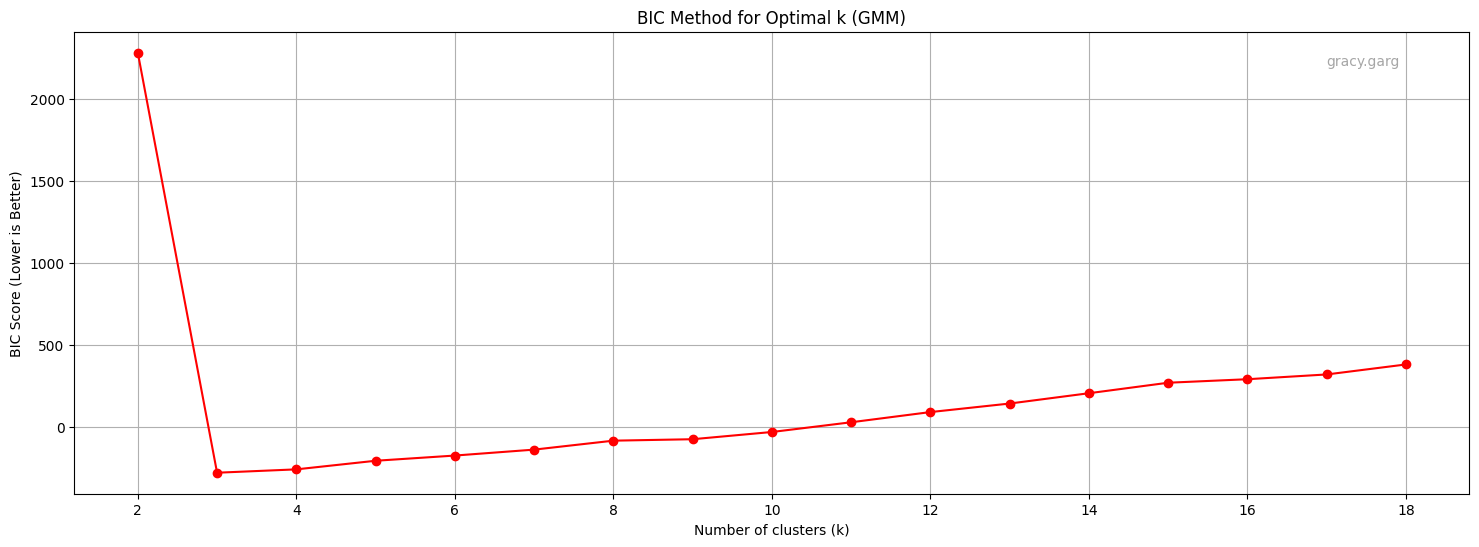

The optimal value of k according to the BIC method is k = 3, as this value minimizes the BIC score.
BIC penalizes complexity more strongly than AIC, so it has chosen the value of k for which the model has both a good fit and is relatively simple (low number of parameters).


In [9]:
K_range = range(2, 19) 
bic_scores = []
sil_scores = []

for k in K_range:
    gmm_sk = GaussianMixture(n_components=k, random_state=seed)
    gmm_sk.fit(X)
    
    # BIC Calculation
    bic_scores.append(gmm_sk.bic(X))
    
    # Silhouette Method
    labels = gmm_sk.predict(X)
    sil_scores.append(silhouette_score(X, labels))

# --- BIC Plot and Analysis ---
plt.figure(figsize=(18, 6))
plt.plot(K_range, bic_scores, 'r-o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('BIC Score (Lower is Better)')
plt.title(f'BIC Method for Optimal k (GMM)')
add_username_to_plot(username)
plt.grid(True)
plt.show()

# Find optimal k based on BIC
best_k_bic = K_range[np.argmin(bic_scores)]
print(f"The optimal value of k according to the BIC method is k = {best_k_bic}, as this value minimizes the BIC score.")
print("BIC penalizes complexity more strongly than AIC, so it has chosen the value of k for which the model has both a good fit and is relatively simple (low number of parameters).")

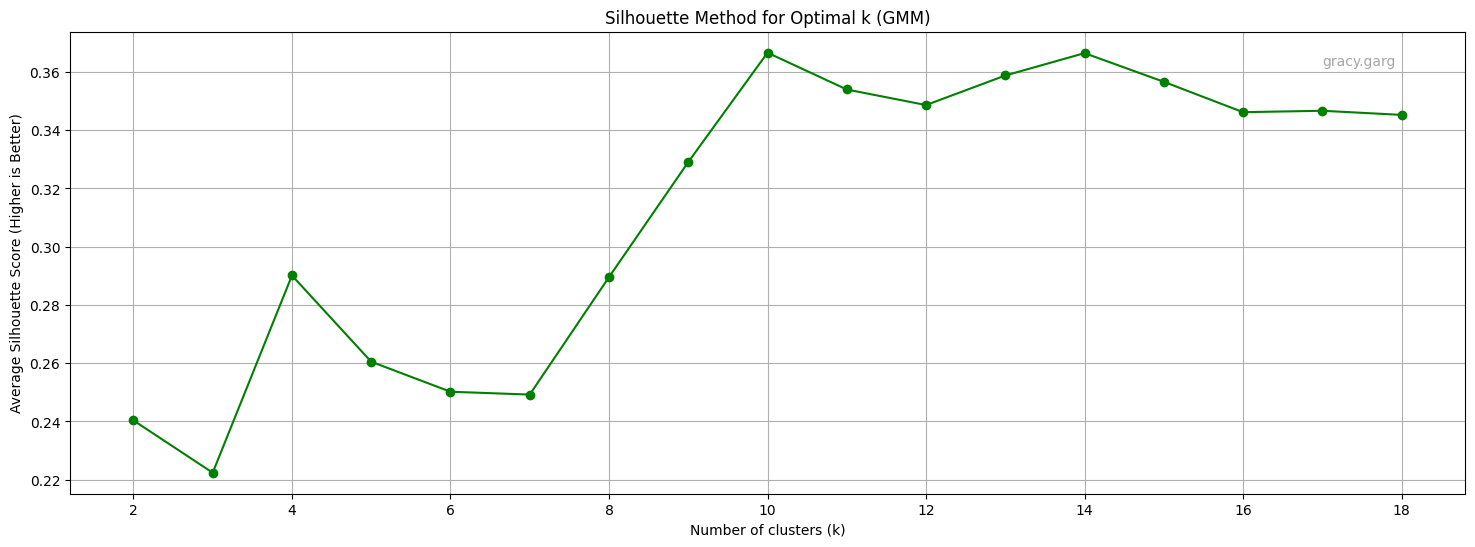

The optimal value of k according to the Silhouette method is k = 10, as this value maximizes the average silhouette score (Score: 0.3666).
This indicates that at k = 10, the clusters are, on average, well-separated and dense. Points are closer to their own cluster center than to any other cluster center, suggesting a good cluster structure.


In [10]:
# Using Silhouette Method 
plt.figure(figsize=(18, 6))
plt.plot(K_range, sil_scores, 'g-o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Average Silhouette Score (Higher is Better)')
plt.title(f'Silhouette Method for Optimal k (GMM)')
add_username_to_plot(username)
plt.grid(True)
plt.show()

# Find optimal k based on Silhouette Score
best_k_sil = K_range[np.argmax(sil_scores)]
max_score_sil = np.max(sil_scores)

print(f"The optimal value of k according to the Silhouette method is k = {best_k_sil}, as this value maximizes the average silhouette score (Score: {max_score_sil:.4f}).")
print(f"This indicates that at k = {best_k_sil}, the clusters are, on average, well-separated and dense. Points are closer to their own cluster center than to any other cluster center, suggesting a good cluster structure.")

# Q4 Image Segmentation

In [11]:
SEGMENT_COLORS = np.array([
    [0, 0, 255],    # Blue (Water)
    [0, 255, 0],  # Forest Green (Vegetation)
    [255, 0, 0] # Red (Land)
])

def preprocess_image(image_path):
    """Loads an image, converts it to RGB, and flattens the pixel data."""
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Could not load image at {image_path}")
    
   
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)      # Convert BGR to RGB
    
    # Store original dimensions for reshaping later
    h, w, d = img_rgb.shape
    
    # Flatten the image data: (H*W, D) where D=3 (R, G, B)
    X_flat = img_rgb.reshape(-1, d).astype(np.float64)
    
    # Scaling the color components for GMM
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_flat)
    
    return X_scaled, X_flat, img_rgb, h, w, d, scaler


def segment_and_plot(image_path, k, seed, username):
    """Loads, segments, and plots the final result for a single image."""
    print(f"--- Processing {image_path} ---")
    
    X_scaled, X_flat, img_rgb, h, w, d, scaler = preprocess_image(image_path)
    gmm_model = GMMCustom(k=k, max_iters=100, tol=1e-4, random_state=seed)
    gmm_model.fit(X_scaled)
    
    labels = gmm_model.predict(X_scaled)
    
    # The GMM means are in the SCALED space. We need to inverse transform them to get the mean R, G, B values of each cluster.
    means_scaled = gmm_model.means
    means_rgb = scaler.inverse_transform(means_scaled).astype(np.uint8)
    
    segmented_flat = means_rgb[labels]
    segmented_image = segmented_flat.reshape(h, w, d)
    
    plt.figure(figsize=(18, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(img_rgb)
    plt.title(f'Original Image: {image_path}')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(segmented_image)
    plt.title(f'GMM Segmentation (k={k})')
    plt.axis('off')
    
    plt.suptitle(f"Image Segmentation Result")
    add_username_to_plot(username)
    plt.tight_layout(rect=[0, 0, 1, 0.95]) 
    plt.show()



### Q4.1 Image Segmentation

In [12]:
k_segment = 3 

# segment_and_plot("satellite_1.png", k_segment, seed, username)
# segment_and_plot("satellite_2.png", k_segment, seed, username)

In [13]:
import os
from matplotlib.ticker import MaxNLocator
def _ensure_uint8_img(img):
    """Ensures image is uint8 for correct display by imshow/cv2."""
    if img.dtype != np.uint8:
        if img.max() > 1.0 and img.max() <= 255.0:
            return img.astype(np.uint8)
        elif img.max() <= 1.0:
            return (img * 255).astype(np.uint8)
        else:
            return np.clip(img, 0, 255).astype(np.uint8)
    return img


def fit_for_video(gmm_model, X, X_flat, img_rgb, h, w, d, scaler):
    """
    Modified fit method that yields segmented image, likelihood, and history after each iteration.
    """
    gmm_model._initialize_parameters(X)
    gmm_model.likelihood_history = []
    previous_likelihood = -np.inf

    for i in range(gmm_model.max_iters):
        responsibilities = gmm_model._expectation_step(X)       # E-step

        gmm_model._maximization_step(X, responsibilities)       # M-step

        # Calculate Likelihood
        current_likelihood = gmm_model.getLikelihood(X)
        gmm_model.likelihood_history.append(current_likelihood)
        
        # Hard Assignment (for segmentation)
        labels = np.argmax(responsibilities, axis=1)
        
        # Inverse transform means to RGB space
        means_rgb = scaler.inverse_transform(gmm_model.means).astype(np.uint8)
        
        # Generate Segmented Image
        segmented_flat = means_rgb[labels]
        segmented_image = segmented_flat.reshape(h, w, d)
        
        yield segmented_image, current_likelihood, i + 1, gmm_model.likelihood_history

        if (current_likelihood - previous_likelihood) < gmm_model.tol and i > 0:      # Check for convergence

            print(f"GMM converged at iteration {i+1}.")
            break
        
        previous_likelihood = current_likelihood


def generate_segmentation_video(image_path,
                                output_filename,
                                k,
                                seed,
                                username,
                                gmm_cls,          
                                max_iters=100,
                                tol=1e-3,
                                fps=5,
                                dpi=100,
                                fig_width_inches=16,
                                fig_height_inches=6,
                                use_palette=False,
                                palette=None):
    """
    Creates a 3-panel per-iteration video showing:
      Left: original image
      Middle: segmented image (cluster means colors)
      Right: log-likelihood vs iteration
    """
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        try:
             X_scaled, X_flat, img_rgb, h, w, d, scaler = preprocess_image(image_path, scale_factor=0.25)
        except NameError:
             raise FileNotFoundError(f"Cannot read image at {image_path}")
        except FileNotFoundError:
             raise FileNotFoundError(f"Cannot read image at {image_path}")
    else:
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w, d = img_rgb.shape

        X_flat = img_rgb.reshape(-1, 3).astype(np.float64)  
        scaler = StandardScaler()
        X = scaler.fit_transform(X_flat)  


    if 'X' not in locals():
         X_flat = img_rgb.reshape(-1, 3).astype(np.float64)  
         scaler = StandardScaler()
         X = scaler.fit_transform(X_flat) 
         
    gmm_model = gmm_cls(k=k, max_iters=max_iters, tol=tol, random_state=seed) # Use 'k' to match GMMCustom init

    # --- Video writer setup ---
    fig_width = int(fig_width_inches * dpi)
    fig_height = int(fig_height_inches * dpi)
    output_dir = os.path.dirname(output_filename)
    if output_dir != "" and not os.path.exists(output_dir):
        os.makedirs(output_dir, exist_ok=True)

    fourcc = cv2.VideoWriter_fourcc(*'mp4v') 
    video_writer = cv2.VideoWriter(output_filename, fourcc, fps, (fig_width, fig_height))
    if not video_writer.isOpened():
        fourcc = cv2.VideoWriter_fourcc(*'XVID')
        video_writer = cv2.VideoWriter(output_filename, fourcc, fps, (fig_width, fig_height))
        if not video_writer.isOpened():
            raise RuntimeError("Failed to open VideoWriter. Check codec/filename.")

    generator = fit_for_video(gmm_model, X, X_flat, img_rgb, h, w, d, scaler)

    if use_palette and (palette is None or len(palette) < k):
        raise ValueError("If use_palette=True you must pass 'palette' with at least k colors.")

    try:
        for segmented_image, current_likelihood, iteration, history in generator:
            seg_img = _ensure_uint8_img(segmented_image)

            # Optionally remap cluster colors to a fixed palette (enhances visibility)
            if use_palette:
                try:
                    # compute labels as nearest mean in scaled space (faster than GMM predict)
                    # Convert means (in scaled space) to RGB space via inverse_transform
                    means_rgb = scaler.inverse_transform(gmm_model.means).astype(np.uint8)
                    flat = seg_img.reshape(-1, 3)
                    
                    # For each pixel in segmented image, find the closest mean color it represents
                    dists = np.linalg.norm(flat[:, None, :].astype(np.float32) - means_rgb[None, :, :].astype(np.float32), axis=2)
                    labels = np.argmin(dists, axis=1)
                    
                    # Map the found label index to the custom palette color
                    mapped = np.array([palette[l] for l in labels], dtype=np.uint8).reshape(h, w, 3)
                    seg_img = mapped
                except Exception as e:
                    print(f"Palette remapping failed: {e}")
                    pass 

            fig, axes = plt.subplots(1, 3, figsize=(fig_width_inches, fig_height_inches), dpi=dpi)
            
            # Left: original
            axes[0].imshow(img_rgb)
            axes[0].set_title("Original")
            axes[0].axis('off')

            # Center: segmented
            axes[1].imshow(seg_img)
            axes[1].set_title(f"Segmented (iter {iteration})")
            axes[1].axis('off')

            # Right: likelihood plot
            ax = axes[2]
            # Use iteration 1 to len(history)
            ax.plot(range(1, len(history) + 1), history, 'b-', label='Log-Likelihood')
            ax.set_xlabel("Iteration")
            ax.set_ylabel("Log-Likelihood")
            ax.set_title("Log-Likelihood vs Iteration")
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
            
            # Add username to segmented panel
            add_username_to_plot(username)

            # Mark current iteration
            ax.scatter([iteration], [current_likelihood], s=60, color='red', zorder=5, label='Current')
            ax.grid(True)
            
            # Set fixed x/y limits for non-jittering plot
            ax.set_xlim(0, max_iters)
            y_min = min(history) if len(history) > 0 else 0
            y_max = max(history) if len(history) > 0 else 1
            ax.set_ylim(y_min - abs(y_min) * 0.1 - 1, y_max + abs(y_max) * 0.1 + 1)

            plt.tight_layout()

            # Draw canvas and convert to image for OpenCV (FIXED BUFFER HANDLING)
            fig.canvas.draw()
            buf = fig.canvas.buffer_rgba()
            frame = np.asarray(buf)  # shape (H, W, 4) RGBA

            if frame.shape[2] == 4:
                frame_bgr = cv2.cvtColor(frame, cv2.COLOR_RGBA2BGR)
            else:
                frame_bgr = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)

            if (frame_bgr.shape[1], frame_bgr.shape[0]) != (fig_width, fig_height):
                frame_bgr = cv2.resize(frame_bgr, (fig_width, fig_height))

            video_writer.write(frame_bgr)
            plt.close(fig)
    finally:
        video_writer.release()

    print(f"Saved video: {output_filename}")

### Q4.2 Dynamic Visualization Video

In [14]:
FIXED_PALETTE = np.array([
    [0, 0, 255],    # Blue for Water
    [34, 139, 34],  # Green for Vegetation
    [210, 180, 140] # Brown/Tan for Land
])

# generate_segmentation_video(
#     image_path="satellite_1.png",
#     output_filename="segmentation_video_1.mp4",
#     k=k_segment,
#     seed=seed,
#     username=username,
#     gmm_cls=GMMCustom, 
#     max_iters=50,      
#     tol=1e-3,
#     # use_palette=True, 
#     # palette=FIXED_PALETTE
# )

In [15]:
# generate_segmentation_video(
#     image_path="satellite_2.png",
#     output_filename="segmentation_video_2.mp4",
#     k=k_segment,
#     seed=seed,
#     username=username,
#     gmm_cls=GMMCustom, 
#     max_iters=50,      
#     tol=1e-3,
#     # use_palette=True, 
#     # palette=FIXED_PALETTE
# )

print("Video generation complete.")

Video generation complete.


Video Link: 

https://iiithydstudents-my.sharepoint.com/:f:/g/personal/gracy_garg_students_iiit_ac_in/Elx5clZvzQlGklwS_DSJqBkBqG_wDPs2LX9bi6-tZfdxfA?e=sDsDnE

# Q5 PCA

### Q5.1 Custom Implementation

In [16]:
class PCACustom:
    def __init__(self, n_components):
        self.n_components = n_components
        self.components = None   # eigenvectors
        self.mean = None
        self.explained_variance = None

    def fit(self, X):
        self.mean = np.mean(X, axis=0)               # Step 1: mean center
        X_centered = X - self.mean

        cov = np.cov(X_centered, rowvar=False)       # Step 2: covariance matrix

        eigvals, eigvecs = np.linalg.eigh(cov)       # Step 3: eigen decomposition

        sorted_idx = np.argsort(eigvals)[::-1]       # Step 4: sort by descending eigenvalue
        eigvals = eigvals[sorted_idx]
        eigvecs = eigvecs[:, sorted_idx]

        self.components = eigvecs[:, :self.n_components]    # Step 5: keep top components
        self.explained_variance = eigvals / np.sum(eigvals)

    def transform(self, X):
        X_centered = X - self.mean
        return np.dot(X_centered, self.components)

    def inverse_transform(self, X_proj):
        return np.dot(X_proj, self.components.T) + self.mean

    def checkPCA(self, X):
        X_proj = self.transform(X)
        return X_proj.shape[1] == self.n_components
    
    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

### Q5.2 PCA on MNIST

In [17]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
mnist = fetch_openml('mnist_784', version=1, cache=True, parser='auto', as_frame=False)
X_full, y_full = mnist.data, mnist.target.astype(int)

subset_X, subset_y = [], []
for digit in range(10):
    idx = np.where(y_full == digit)[0][:100]  
    subset_X.append(X_full[idx])
    subset_y.append(y_full[idx])

subset_X = np.vstack(subset_X)
subset_y = np.hstack(subset_y)

X_flat = subset_X.reshape(subset_X.shape[0], -1).astype(np.float64)

print("Subset shape:", X_flat.shape)  


Subset shape: (1000, 784)


In [18]:
dims = [500, 300, 150, 30]
pca_models = {}
X_proj = {}
X_reconstructed = {}

for d in dims:
    pca = PCACustom(n_components=d)
    pca.fit(X_flat)
    X_proj[d] = pca.transform(X_flat)
    X_reconstructed[d] = pca.inverse_transform(X_proj[d])
    pca_models[d] = pca
    print(f"Dim={d}, check={pca.checkPCA(X_flat)}")


Dim=500, check=True
Dim=300, check=True
Dim=150, check=True
Dim=30, check=True


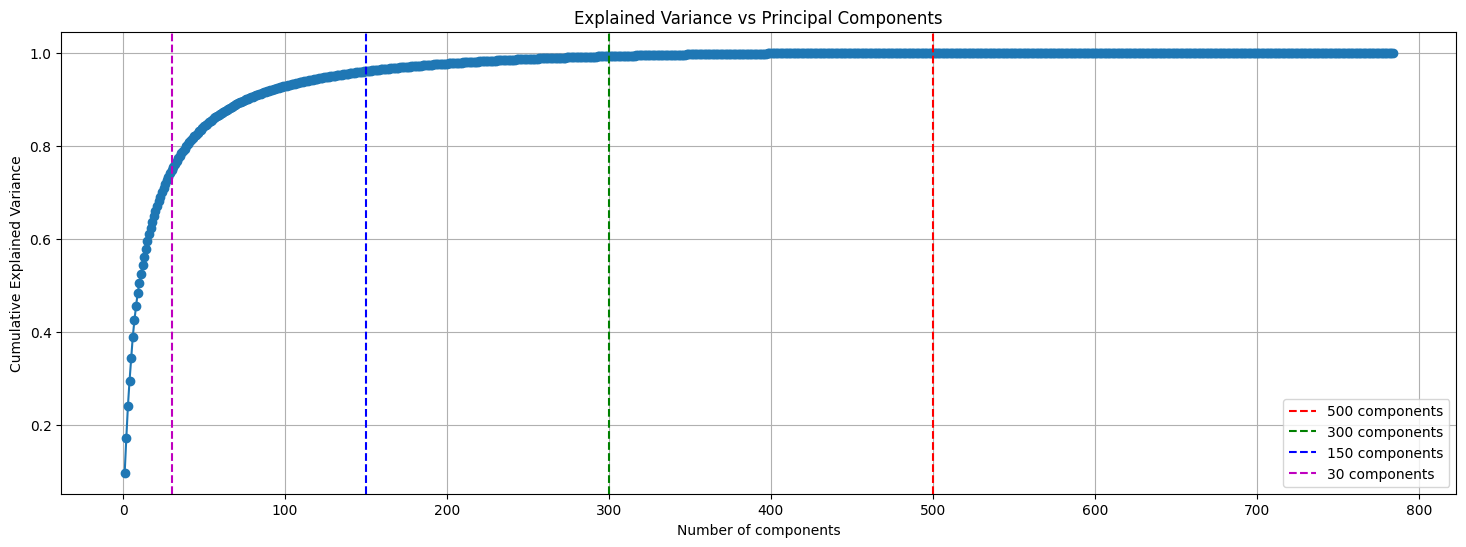

In [19]:
# Use the largest PCA model to plot full curve
largest_pca = pca_models[500]  # already computed eigenvalues
explained = np.cumsum(largest_pca.explained_variance)

plt.figure(figsize=(18, 6))
plt.plot(np.arange(1, len(explained)+1), explained, marker='o')
plt.axvline(500, color='r', linestyle='--', label="500 components")
plt.axvline(300, color='g', linestyle='--', label="300 components")
plt.axvline(150, color='b', linestyle='--', label="150 components")
plt.axvline(30, color='m', linestyle='--', label="30 components")
plt.xlabel("Number of components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Explained Variance vs Principal Components")
plt.legend()
plt.grid(True)
plt.show()


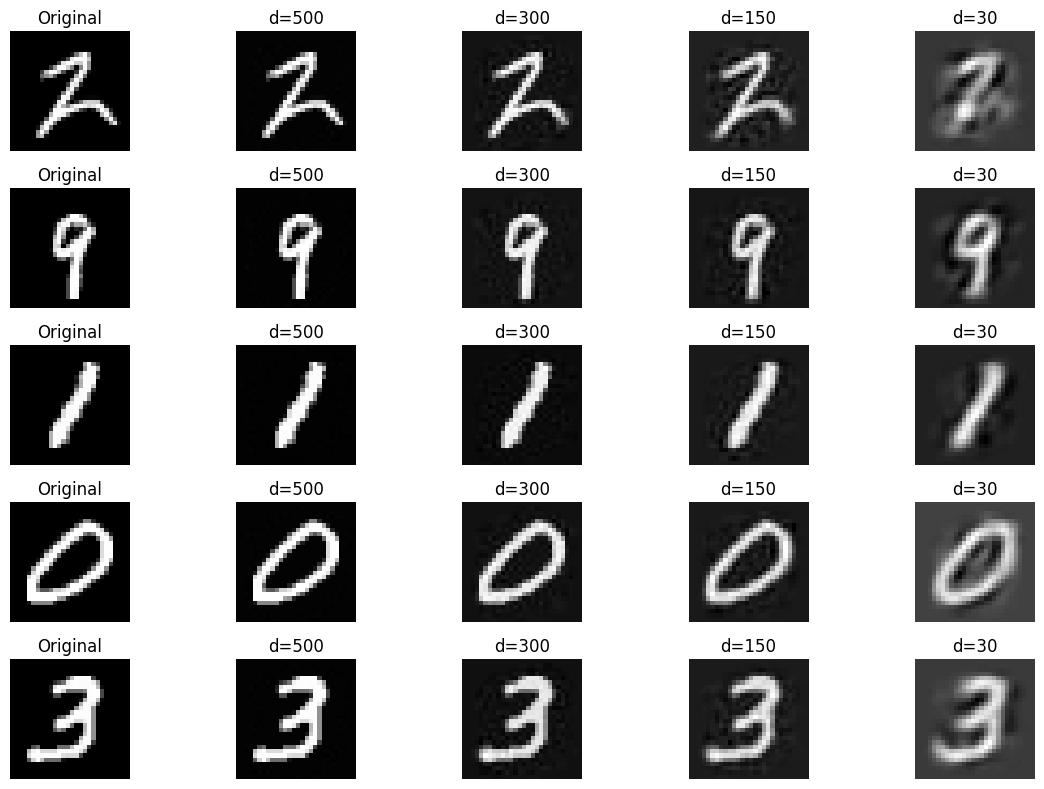

In [20]:
indices = random.sample(range(1000), 5)

plt.figure(figsize=(12, 8))

for idx, img_idx in enumerate(indices):
    # Original
    plt.subplot(len(indices), len(dims)+1, idx*(len(dims)+1)+1)
    plt.imshow(X_flat[img_idx].reshape(28,28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructions
    for j, d in enumerate(dims):
        recon = X_reconstructed[d][img_idx].reshape(28,28)
        plt.subplot(len(indices), len(dims)+1, idx*(len(dims)+1)+2+j)
        plt.imshow(recon, cmap="gray")
        plt.title(f"d={d}")
        plt.axis("off")

plt.tight_layout()
plt.show()


# Q6 PCA + Classification

In [21]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

### Q6.1 Data Loading and Preparation

In [22]:
digits = load_digits()
X, y = digits.data, digits.target  

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)


Train shape: (1437, 64) Test shape: (360, 64)


### Q6.2 Dimensionality Reduction with PCA

In [23]:
n_components_list = [2, 5, 10, 20, 30, 40, 50, 64]
k_values = [5, 25, 50, 100]
results = {k: [] for k in k_values}

### Q6.3 Classification with KNN

In [24]:
for n in n_components_list:
    pca = PCACustom(n_components=n)
    pca.fit(X_train)
    X_train_pca = pca.transform(X_train)
    X_test_pca = pca.transform(X_test)

    for k in k_values:
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_train_pca, y_train)
        y_pred = knn.predict(X_test_pca)
        acc = accuracy_score(y_test, y_pred)
        results[k].append(acc)

### Q6.4 Visualization and Analysis

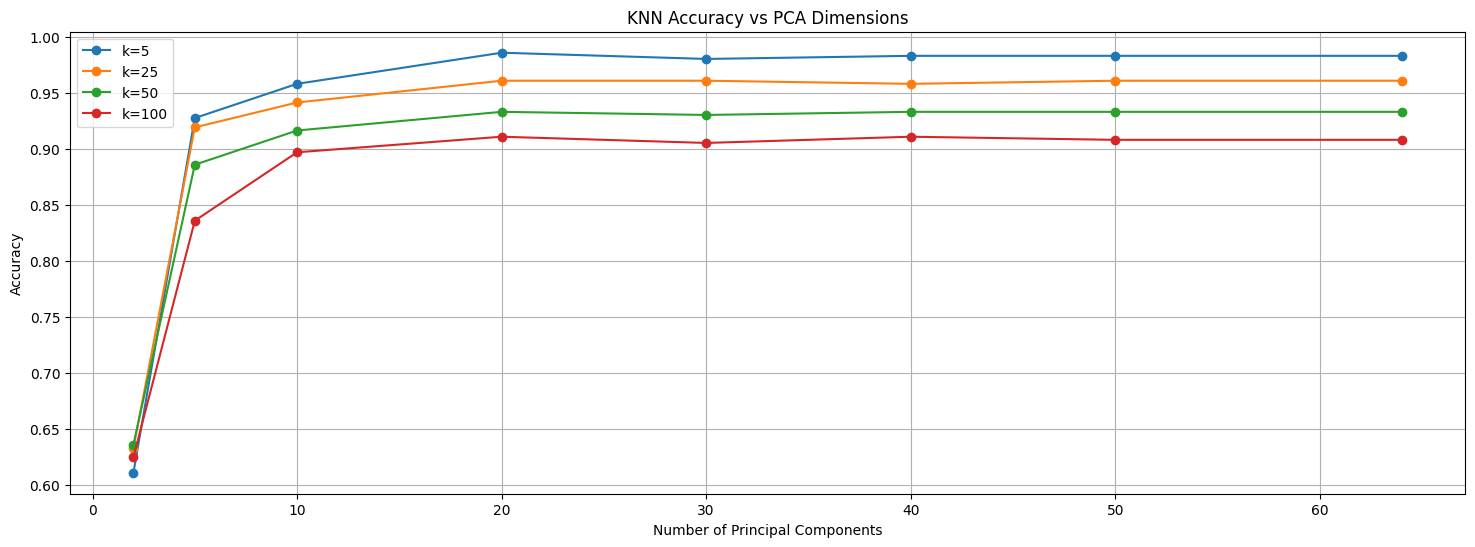

In [25]:
plt.figure(figsize=(18,6))
for k in k_values:
    plt.plot(n_components_list, results[k], marker='o', label=f'k={k}')

plt.title("KNN Accuracy vs PCA Dimensions")
plt.xlabel("Number of Principal Components")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

-The accuracy of the KNN classifier improves as the number of principal components increases, with significant gains up to around 20–30 components.  
-Beyond this point, the accuracy stabilises, indicating a **diminishing return** as most useful variance is already captured.  
-Smaller values of k (eg. 5) tend to perform better in lower dimensions but are more sensitive to noise, while larger k values provide smoother but sometimes less accurate results.  
-Overall, the optimal performance is achieved with around 20 components, after which adding more dimensions does not significantly improve accuracy.  

# Q7 Enhancing Clustering Accuracy with Data Transformation

In [26]:
from collections import Counter
from scipy.ndimage import center_of_mass, affine_transform, gaussian_filter
%pip install scikit-image
from skimage.measure import moments_central, moments_normalized, moments_hu
from skimage.draw import disk
from sklearn.metrics import adjusted_rand_score

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


### Q7.1 Input

In [27]:
X_mod = np.load("X_modified.npy")   # shape (1000, 28, 28)
y_true = np.load("y_true.npy")

### Q7.2 Expected Output

Modified dataset shape: (1000, 28, 28) (1000,)


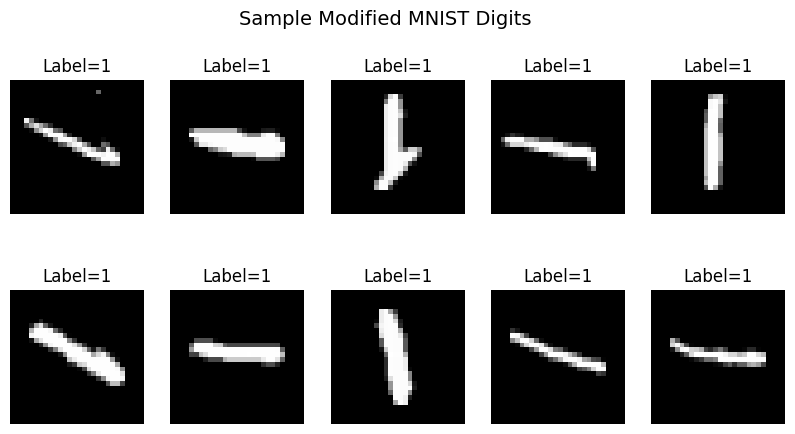

In [28]:
print("Modified dataset shape:", X_mod.shape, y_true.shape)

# Visualize some samples
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_mod[i], cmap="gray")
    ax.set_title(f"Label={y_true[i]}")
    ax.axis("off")
plt.suptitle("Sample Modified MNIST Digits", fontsize=14)
plt.show()

# Observations
The modified dataset differs noticeably from standard MNIST. As shown in the sample above (digit 1), the digits are not uniformly centered or aligned. Many of these appear rotated, slanted, or horizontally stretched. The stroke thickness varies, and in some cases extra background noise pixels are visible. Unlike the clean, upright “1” in the original MNIST, these altered digits are distorted and inconsistent, which makes clustering significantly more challenging.

Clustering Accuracy AFTER preprocessing: 0.6360
Clustering Accuracy BEFORE preprocessing: 0.5570


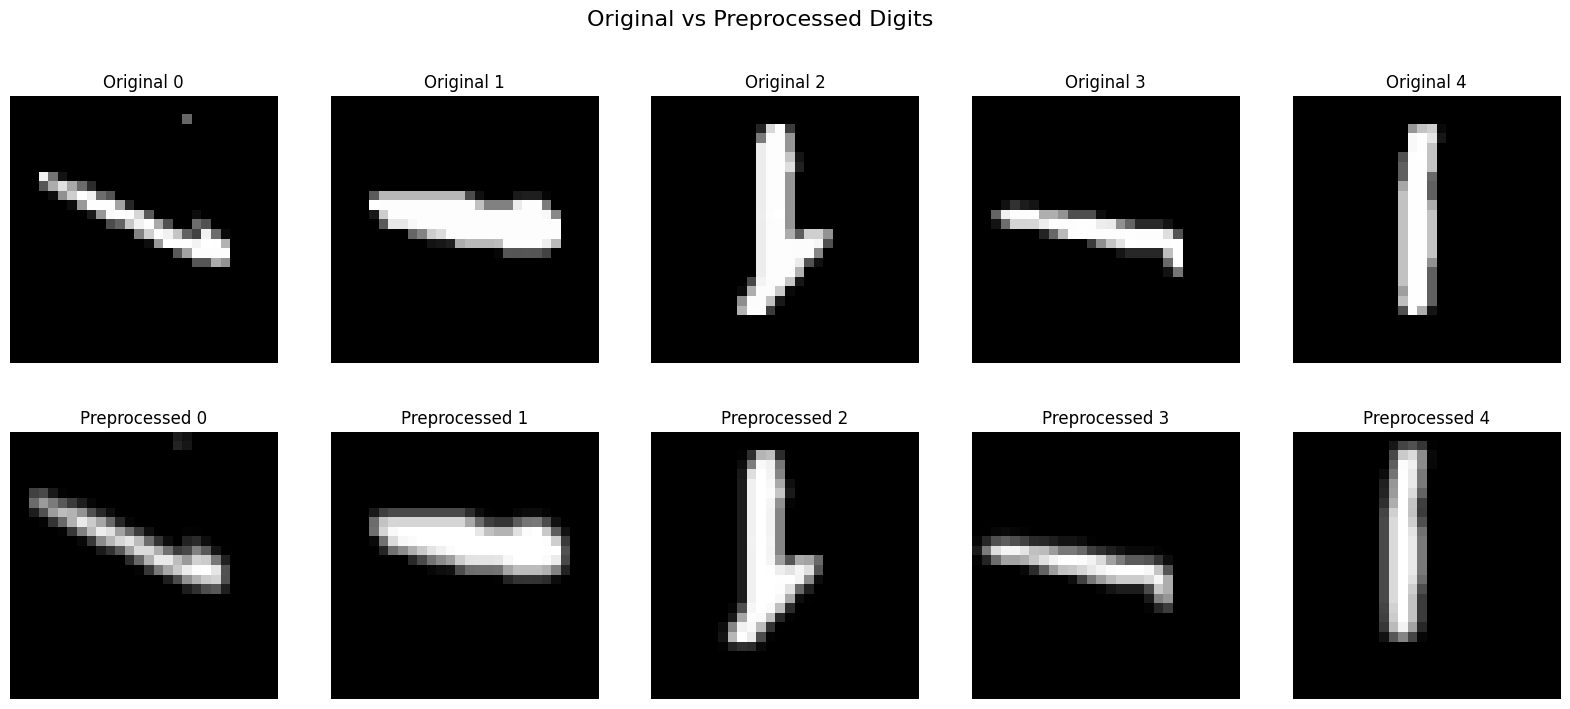

In [29]:
# -------------------------------
# 1. Preprocessing Functions
# -------------------------------
def normalize(img):
    img = img.astype(np.float32) / 255.0
    return np.clip(img, 0.0, 1.0)

def center_image(img):
    w = np.clip(img, 0.0, None)
    cy, cx = center_of_mass(w > 0)
    if np.isnan(cy) or np.isnan(cx):
        return img
    shift_y, shift_x = np.array(img.shape) / 2 - np.array([cy, cx])
    out = affine_transform(img, matrix=np.eye(2), offset=[shift_y, shift_x], order=1, mode='constant', cval=0.0)
    return np.clip(out, 0.0, 1.0)

# def deskew(img):
#     r, c = np.meshgrid(np.arange(img.shape[0]), np.arange(img.shape[1]), indexing='ij')
#     w = np.clip(img, 0.0, None)
#     total = w.sum()
#     if total <= 0:
#         return img
#     cx = (c * w).sum() / total
#     cy = (r * w).sum() / total
#     x = c.flatten() - cx
#     y = r.flatten() - cy
#     w_flat = w.flatten()
#     cov_xx = np.sum(w_flat * x * x) / total
#     cov_xy = np.sum(w_flat * x * y) / total
#     if cov_xx <= 1e-8:
#         return img
#     alpha = cov_xy / cov_xx
#     affine = np.array([[1, 0], [alpha, 1]], dtype=np.float32)
#     out = affine_transform(img, affine, offset=[0, 0], order=1, mode='constant', cval=0.0)
#     return np.clip(out, 0.0, 1.0)

# def hist_eq(img):
#     return cv2.equalizeHist((img*255).astype(np.uint8)) / 255.0

def preprocess(img):
    img = normalize(img)
    img = center_image(img)
    # img = deskew(img)
    # img = hist_eq(img)
    return img

# -------------------------------
# 2. Hu Moments (Rotation-invariant)
# -------------------------------
def compute_hu_features(img):
    binary = (img > 0.5).astype(np.uint8)
    if np.sum(binary) == 0:
        # Return zeros or NaNs for blank images
        return np.zeros(7)
    m = moments_central(binary)
    n = moments_normalized(m)
    hu = moments_hu(n)
    return np.log(np.abs(hu) + 1e-8)

# -------------------------------
# 3. Clustering Accuracy Function
# -------------------------------
def clustering_accuracy(y_true, y_pred, k=10):
    mapping = {}
    for cluster in range(k):
        mask = y_pred == cluster
        if np.sum(mask) == 0:
            continue
        true_labels = y_true[mask]
        most_common = Counter(true_labels).most_common(1)[0][0]
        mapping[cluster] = most_common
    y_mapped = np.array([mapping.get(c, -1) for c in y_pred])
    return np.mean(y_mapped == y_true)

# -------------------------------
# 4. Apply preprocessing & extract features
# -------------------------------
X_trans = np.array([preprocess(img) for img in X_mod])
X_hu = np.array([compute_hu_features(img) for img in X_trans])
X_hu_scaled = StandardScaler().fit_transform(X_hu)

# -------------------------------
# 5. PCA
# -------------------------------
pca = PCACustom(n_components=7)  # Hu moments are 7-dimensional, PCA mainly for visualization
X_pca = pca.fit_transform(X_hu_scaled)

# -------------------------------
# 6. K-Means Clustering
# -------------------------------
kmeans = KMeansCustom(k=10, random_state=42) 
kmeans.fit(X_pca)
labels_after = kmeans.predict(X_pca)         

# -------------------------------
# 7. Metrics
# -------------------------------
acc_after = clustering_accuracy(y_true, labels_after, k=10)
print(f"Clustering Accuracy AFTER preprocessing: {acc_after:.4f}")

# -------------------------------
# 8. Clustering BEFORE preprocessing
# -------------------------------
# Flatten raw images
X_flat = X_mod.reshape(len(X_mod), -1)
X_flat_scaled = StandardScaler().fit_transform(X_flat)

# PCA
X_flat_pca = PCACustom(n_components=50).fit_transform(X_flat_scaled)

# K-Means
kmeans_before = KMeansCustom(k=10, random_state=42)
kmeans_before.fit(X_flat_pca)
labels_before = kmeans_before.predict(X_flat_pca)

# Metrics
acc_before = clustering_accuracy(y_true, labels_before, k=10)

print(f"Clustering Accuracy BEFORE preprocessing: {acc_before:.4f}")
# -------------------------------
# 9. Visualize before vs after preprocessing
# -------------------------------
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for i in range(5):
    axes[0, i].imshow(X_mod[i], cmap="gray")
    axes[0, i].set_title(f"Original {i}")
    axes[0, i].axis("off")
    axes[1, i].imshow(X_trans[i], cmap="gray")
    axes[1, i].set_title(f"Preprocessed {i}")
    axes[1, i].axis("off")
plt.suptitle("Original vs Preprocessed Digits", fontsize=16)
plt.show()


# Why these transformations work?
Here I have applied normalization and centering. 

While normalization ensures all pixel values are on the same scale, reducing the effect of brightness/contrast differences.

Clustering algorithms like KMeans are sensitive to spatial alignment : two images of the same digit can look very different if one is shifted.
By computing the center of mass of the digit and shifting it to the image center, it aligns all digits consistently.

This is to remove irrelevant variations (brightness, position) while keeping the true structure of digits intact.This makes it easier for clustering algorithms to distinguish digits based on shape, not distortions.

We also observe that the dataset is very skewed/rotated. To handle this, we extract rotation-invariant features using Hu moments.Each image is represented as a 7-dimensional feature vector, capturing its essential shape characteristics.Hu moments are mathematical descriptors derived from image moments that remain invariant to translation, rotation, and scale.


# What else?
Features are scaled using StandardScaler to standardize their distribution.PCA (Principal Component Analysis) is applied to reduce dimensionality for visualization and improve K-Means performance.K-Means clustering is applied both before and after preprocessing:

# Metrics used 
Clustering Accuracy: Maps each cluster to the most frequent true label and computes the percentage of correctly clustered images.